
[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\amiru\Documents\hs4002_ay26\.venv\Scripts\python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


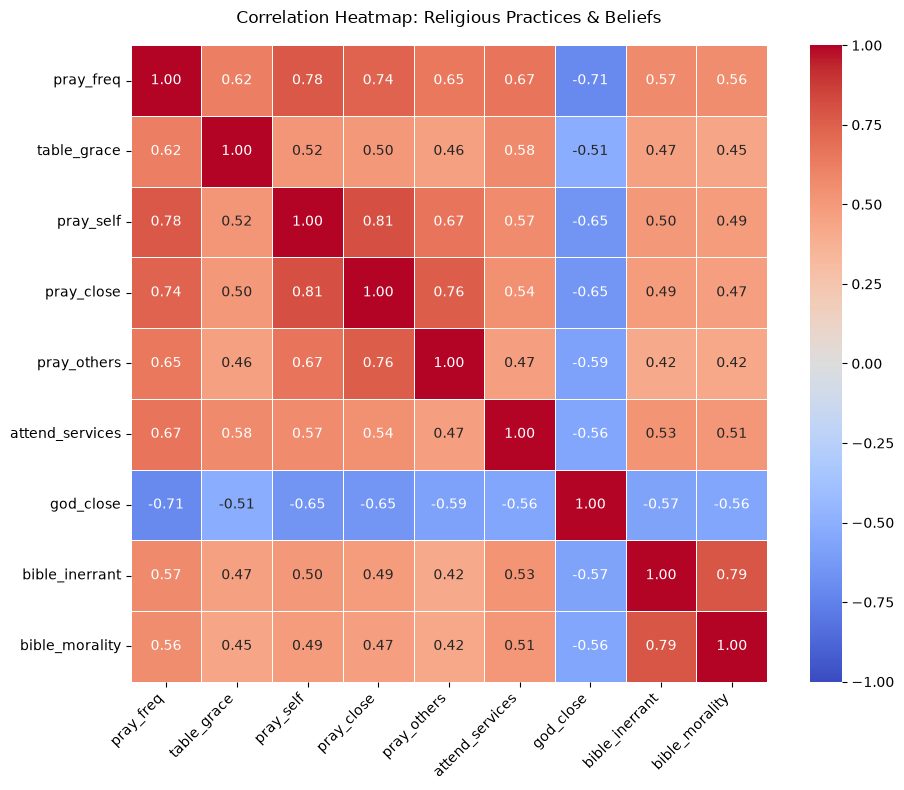

In [4]:
%pip install seaborn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_stata("chrisu.DTA", convert_categoricals=False)

# map variable codes to readable labels
var_mapping = {
    # Religious practices
    "V25": "pray_freq",  # About how often do you pray?
    "V26": "table_grace",  # Table prayers of grace before/after meals
    "V27": "pray_self",  # Pray about own personal needs
    "V28": "pray_close",  # Pray about needs of people close to you
    "V29": "pray_others",  # Pray about needs of others / current affairs
    "V34": "attend_services",  # How often do you attend religious services now?
    # Section B: Religious beliefs
    "V30": "god_close",  # How close do you feel to God most of the time?
    "V39": "bible_inerrant",  # Bible contains no errors / infallible Word of God
    "V41": "bible_morality",  # Bible is the final and complete guide to morality
}

# subset and rename columns
subset_df = df[list(var_mapping.keys())].rename(columns=var_mapping)

# Optional: Convert any special numeric missing codes (e.g., negative values) to NaN
# subset_df = subset_df.where(subset_df >= 0)

# correlation matrix --> spearman correlation
corr_matrix = subset_df.corr(method="pearson")
# correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
)

plt.title("Correlation Heatmap: Religious Practices & Beliefs", pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from stargazer.stargazer import Stargazer

# 1. Load and rename
df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
var_mapping = {
    # Religious practices
    "V25": "pray_freq",        # About how often do you pray?
    "V26": "table_grace",      # Table prayers of grace before/after meals
    "V27": "pray_self",        # Pray about own personal needs
    "V28": "pray_close",       # Pray about needs of people close to you
    "V29": "pray_others",      # Pray about needs of others / current affairs
    "V34": "attend_services",  # How often do you attend religious services now?
    # Religious beliefs
    "V30": "god_close",        # How close do you feel to God most of the time?
    "V39": "bible_inerrant",   # Bible contains no errors / infallible Word of God
    "V41": "bible_morality",   # Bible is the final and complete guide to morality
    # Outcome ingredient
    "V79": "drug_freq",        # illegal drug use
}
df = df.rename(columns=var_mapping)
df["god_close"] = 6 - df["god_close"]       # V30: 1 = Very close ... 5 = No closeness -> now 5 = Very close

# 2. Dependent variable: 1 = any illegal drug use (code > 0), 0 = none
df["drug_use"] = np.where(df["drug_freq"].isna(), np.nan, (df["drug_freq"] > 0).astype(int))
print(df["drug_use"].value_counts(dropna=False))   # expect 3221 zeros, 230 ones, 79 missing

# 3. Independent variables
practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs   = ["god_close", "bible_inerrant", "bible_morality"]

# 4. One common sample
cd = df[["drug_use"] + practices + beliefs].dropna().copy()
print("N =", len(cd), "| drug_use = 1:", int(cd["drug_use"].sum()), f"({cd['drug_use'].mean():.1%})")

# 5. Logit
m_drug = smf.logit("drug_use ~ " + " + ".join(practices + beliefs), data=cd).fit(disp=0)
print(m_drug.summary())

# 6. Odds ratios with 95% confidence intervals
or_table = pd.DataFrame({
    "OR": np.exp(m_drug.params),
    "CI_low": np.exp(m_drug.conf_int()[0]),
    "CI_high": np.exp(m_drug.conf_int()[1]),
    "p": m_drug.pvalues,
}).round(3)
print(or_table)

# 7. Average marginal effects (percentage points)
ame = m_drug.get_margeff(at="overall").summary_frame()
print((ame[["dy/dx", "Pr(>|z|)"]] * [100, 1]).round(3).rename(columns={"dy/dx": "AME (pp)", "Pr(>|z|)": "p"}))

# 8. Stargazer table
sg_drug = Stargazer([m_drug])
sg_drug.dependent_variable_name("Illegal Drug Use")
sg_drug.covariate_order(practices + beliefs + ["Intercept"])
sg_drug.rename_covariates({
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "bible_morality": "BELIEFS: Bible as Moral Guide",
})
sg_drug.add_custom_notes(["Logit coefficients (log-odds). Standard errors in parentheses."])
sg_drug

drug_use
0.0    3221
1.0     230
NaN      79
Name: count, dtype: int64
N = 2992 | drug_use = 1: 179 (6.0%)
                           Logit Regression Results                           
Dep. Variable:               drug_use   No. Observations:                 2992
Model:                          Logit   Df Residuals:                     2982
Method:                           MLE   Df Model:                            9
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.04581
Time:                        14:14:41   Log-Likelihood:                -646.61
converged:                       True   LL-Null:                       -677.66
Covariance Type:            nonrobust   LLR p-value:                 5.311e-10
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -1.8227      0.226     -8.060      0.000      -2.266      -1.379
pray_freq

Base rate of drug use: 6.0%

Average marginal effects, percentage points (full model)


,AME (pp),CI low,CI high,p,sig
variable,,,,,
PRACTICES: Praying Frequency,-0.97,-1.98,0.04,0.06,*
PRACTICES: Saying Grace,-0.21,-1.25,0.83,0.69,
PRACTICES: Praying for Self,1.03,-0.16,2.23,0.09,*
PRACTICES: Praying for Close People,-1.11,-2.40,0.17,0.09,*
PRACTICES: Praying for Others,0.72,-0.38,1.83,0.20,
PRACTICES: Attending Services,-1.03,-1.77,-0.28,0.01,***
BELIEFS: Closeness to God,0.22,-0.76,1.19,0.66,
BELIEFS: Bible Inerrancy,0.36,-0.69,1.40,0.51,
BELIEFS: Bible as Moral Guide,-1.15,-2.20,-0.09,0.03,**



Average marginal effects, percentage points (index model)


,AME (pp),CI low,CI high,p,sig
variable,,,,,
Practices index (per 1 SD),-2.16,-3.75,-0.57,0.01,***
Beliefs index (per 1 SD),-1.49,-2.91,-0.07,0.04,**


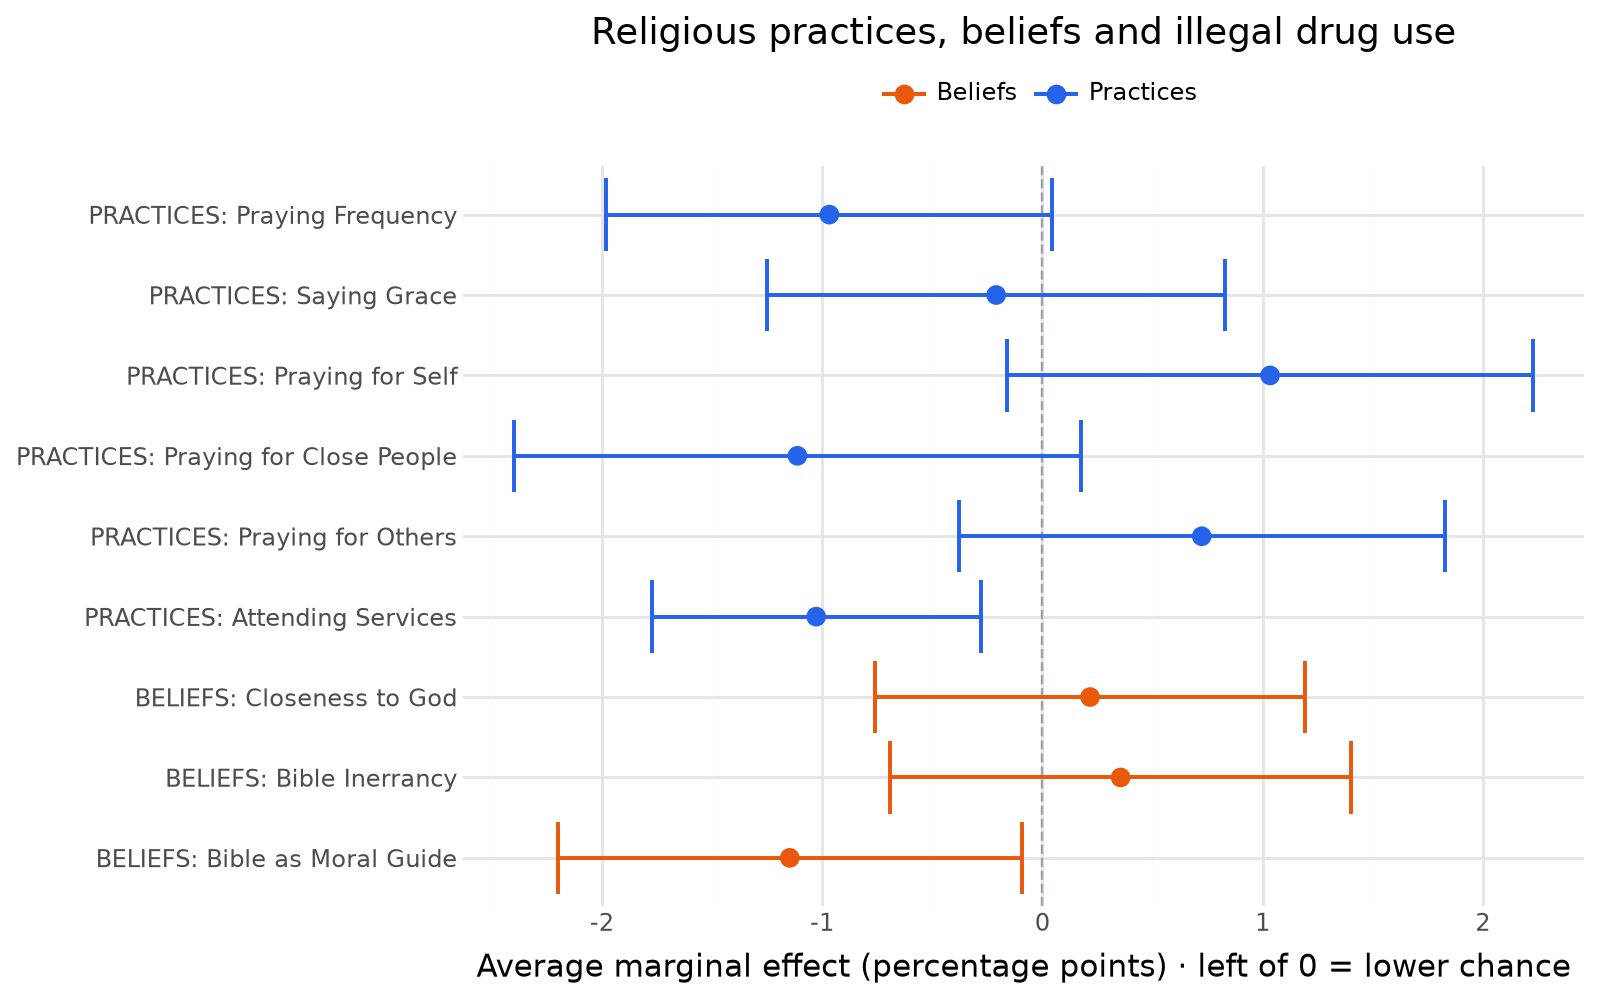

In [6]:
import plotnine as p9

# Readable labels (includes the new Bible-morality item)
item_labels = {
    "pray_freq": "PRACTICES: Praying Frequency",
    "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self",
    "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others",
    "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God",
    "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "bible_morality": "BELIEFS: Bible as Moral Guide",
}
BLUE, ORANGE, MUTED = "#2563EB", "#EA580C", "#9CA3AF"

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def ame_frame(model, names):
    # AME = change in the PROBABILITY of drug use for a 1-unit increase, averaged over every student
    me = model.get_margeff(at="overall").summary_frame()
    return pd.DataFrame({
        "variable": [names.get(v, v) for v in me.index],
        "AME (pp)": me["dy/dx"] * 100,
        "CI low":   me["Conf. Int. Low"] * 100,
        "CI high":  me["Cont. Int. Hi."] * 100,     # statsmodels' own spelling, keep as is
        "p":        me["Pr(>|z|)"],
    }).set_index("variable")

print(f"Base rate of drug use: {cd['drug_use'].mean():.1%}")

# Table 1: full 9-item model
ame_drug = ame_frame(m_drug, item_labels)
ame_drug["sig"] = ame_drug["p"].map(stars)
print("\nAverage marginal effects, percentage points (full model)")
display(ame_drug.round(2))

# Table 2: practices index vs beliefs index (avoids the overlap between items)
z = (cd[practices + beliefs] - cd[practices + beliefs].mean()) / cd[practices + beliefs].std()
cd["practice_index"] = z[practices].mean(axis=1)
cd["belief_index"]   = z[beliefs].mean(axis=1)
m_drug_idx = smf.logit("drug_use ~ practice_index + belief_index", data=cd).fit(disp=0)

index_names = {"practice_index": "Practices index (per 1 SD)", "belief_index": "Beliefs index (per 1 SD)"}
ame_drug_idx = ame_frame(m_drug_idx, index_names)
ame_drug_idx["sig"] = ame_drug_idx["p"].map(stars)
print("\nAverage marginal effects, percentage points (index model)")
display(ame_drug_idx.round(2))

# Chart: AME with 95% CI for each of the 9 items
plot_df = ame_drug.reset_index()
plot_df["group"] = np.where(plot_df["variable"].str.startswith("PRACTICES"), "Practices", "Beliefs")
plot_df["variable"] = pd.Categorical(plot_df["variable"], categories=[item_labels[v] for v in practices + beliefs][::-1])
chart_drug = (p9.ggplot(plot_df, p9.aes(x="AME (pp)", y="variable", color="group"))
              + p9.geom_vline(xintercept=0, color=MUTED, linetype="dashed")
              + p9.geom_errorbarh(p9.aes(xmin="CI low", xmax="CI high"), height=0, size=0.8)
              + p9.geom_point(size=3)
              + p9.scale_color_manual(values={"Practices": BLUE, "Beliefs": ORANGE})
              + p9.labs(title="Religious practices, beliefs and illegal drug use",
                        x="Average marginal effect (percentage points) · left of 0 = lower chance", y="", color="")
              + p9.theme_minimal() + p9.theme(legend_position="top", figure_size=(8, 5)))
chart_drug

     eigenvalue  % variance  cumulative %
PC1        5.48       60.88         60.88
PC2        1.02       11.35         72.23
PC3        0.69        7.63         79.86
PC4        0.44        4.85         84.71
PC5        0.40        4.45         89.16
PC6        0.35        3.93         93.09
PC7        0.23        2.50         95.59
PC8        0.22        2.40         97.99
PC9        0.18        2.01        100.00

Kaiser rule (eigenvalue > 1): keep 2 component(s)


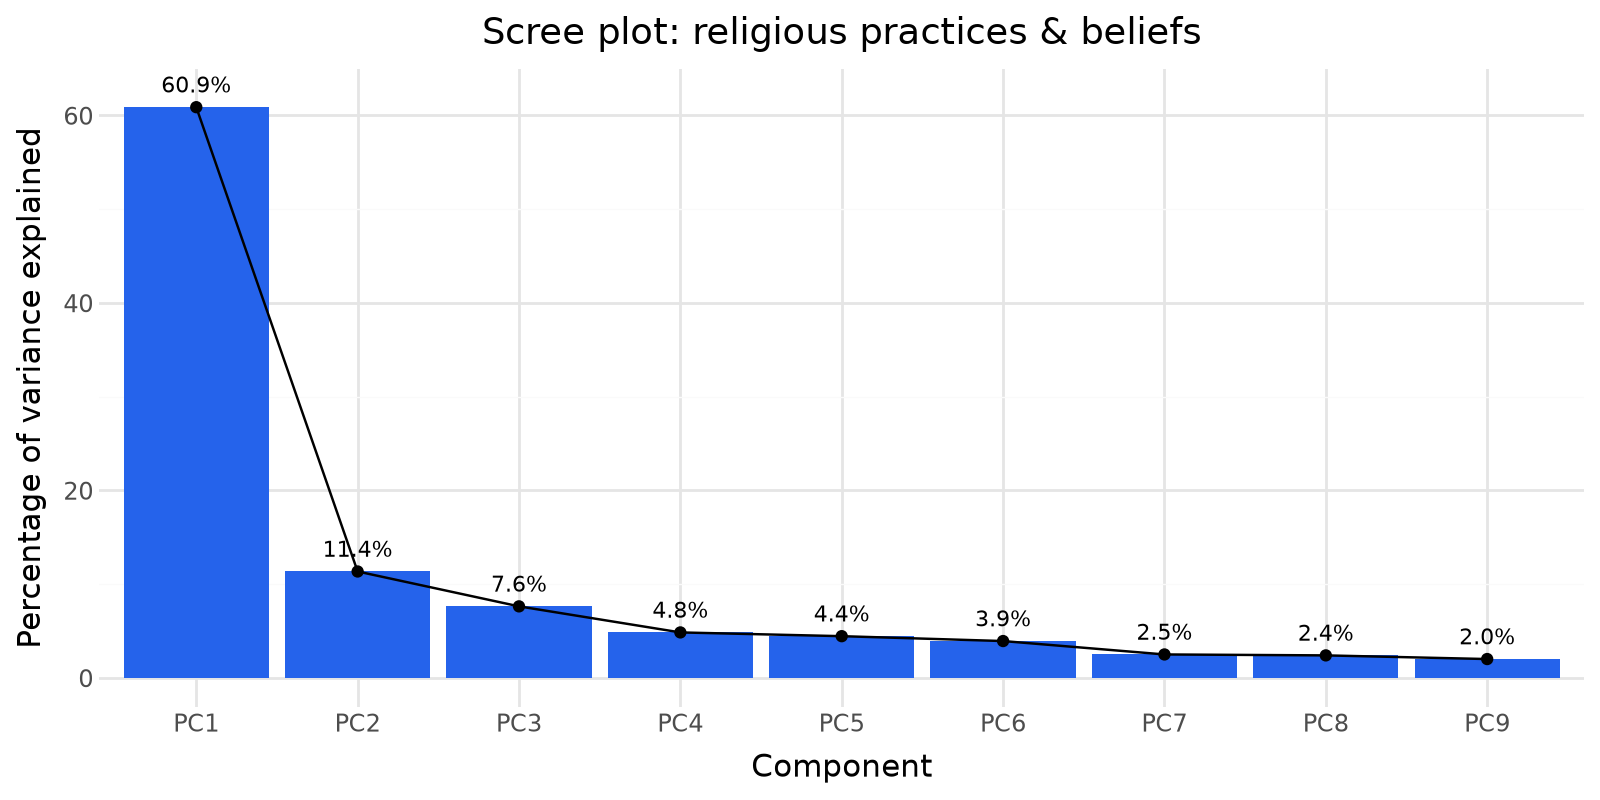


Loadings (|value| > 0.3 is meaningful)


,PC1,PC2
PRACTICES: Praying Frequency,0.88,0.10
PRACTICES: Saying Grace,0.69,-0.06
PRACTICES: Praying for Self,0.83,0.28
PRACTICES: Praying for Close People,0.83,0.37
PRACTICES: Praying for Others,0.75,0.40
PRACTICES: Attending Services,0.78,-0.11
BELIEFS: Closeness to God,0.80,-0.00
BELIEFS: Bible Inerrancy,0.73,-0.55
BELIEFS: Bible as Moral Guide,0.71,-0.57



Base rate of drug use: 6.0%
PC1: OR = 0.598 [0.512, 0.698]  p = 0.000  AME = -2.85 pp
PC2: OR = 1.171 [0.999, 1.372]  p = 0.051  AME = +0.87 pp


In [7]:
items = practices + beliefs     # 9 items

# 1. Standardise items (mean 0, SD 1), then PCA on the correlation matrix
z = (cd[items] - cd[items].mean()) / cd[items].std()
eigval, eigvec = np.linalg.eigh(np.corrcoef(z.T))
order = eigval.argsort()[::-1]                     # largest component first
eigval, eigvec = eigval[order], eigvec[:, order]

# 2. Scree table: how much variance each component explains
pcs = [f"PC{i+1}" for i in range(len(items))]
scree = pd.DataFrame({
    "eigenvalue": eigval,
    "% variance": eigval / eigval.sum() * 100,
    "cumulative %": (eigval / eigval.sum() * 100).cumsum(),
}, index=pcs).round(2)
print(scree)
n_keep = int((eigval > 1).sum())
print(f"\nKaiser rule (eigenvalue > 1): keep {n_keep} component(s)")

# 3. Scree plot
scree_df = scree.reset_index().rename(columns={"index": "PC"})
scree_df["PC"] = pd.Categorical(scree_df["PC"], categories=pcs)
scree_df["label"] = scree_df["% variance"].round(1).astype(str) + "%"
scree_plot = (p9.ggplot(scree_df, p9.aes("PC", "% variance"))
              + p9.geom_col(fill=BLUE)
              + p9.geom_line(p9.aes(group=1)) + p9.geom_point()
              + p9.geom_text(p9.aes(label="label"), va="bottom", nudge_y=1, size=8)
              + p9.labs(title="Scree plot: religious practices & beliefs", x="Component",
                        y="Percentage of variance explained")
              + p9.theme_minimal() + p9.theme(figure_size=(8, 4)))
display(scree_plot)

# 4. Loadings: correlation of each item with PC1 and PC2
loadings = pd.DataFrame(eigvec[:, :2] * np.sqrt(eigval[:2]), index=items, columns=["PC1", "PC2"])
# Signs are arbitrary in PCA, so fix them: PC1 high = more religious, PC2 high = more "pray for others"
sign = np.array([np.sign(loadings["PC1"].sum()), np.sign(loadings.loc["pray_others", "PC2"])])
loadings = loadings * sign
loadings.index = [item_labels[v] for v in items]
print("\nLoadings (|value| > 0.3 is meaningful)")
display(loadings.round(2))

# 5. Component scores for each student (standardised, so 1 unit = 1 SD)
scores = (z.values @ eigvec[:, :2]) * sign
cd["PC1"] = scores[:, 0] / scores[:, 0].std(ddof=1)
cd["PC2"] = scores[:, 1] / scores[:, 1].std(ddof=1)

# 6. Logit: drug use on the components
m_pc1 = smf.logit("drug_use ~ PC1", data=cd).fit(disp=0)          # main component only
m_pc2 = smf.logit("drug_use ~ PC1 + PC2", data=cd).fit(disp=0)    # adds the secondary component

sg_pca = Stargazer([m_pc1, m_pc2])
sg_pca.dependent_variable_name("Illegal Drug Use")
sg_pca.custom_columns(["PC1 only", "PC1 + PC2"], [1, 1])
sg_pca.rename_covariates({"PC1": "PC1: General religiosity", "PC2": "PC2: Secondary component"})
sg_pca.add_custom_notes(["Components standardised (per 1 SD). Standard errors in parentheses."])
display(sg_pca)

# 7. Odds ratios and average marginal effects
ci = np.exp(m_pc2.conf_int())
me = m_pc2.get_margeff(at="overall").summary_frame()
print(f"\nBase rate of drug use: {cd['drug_use'].mean():.1%}")
for v in ["PC1", "PC2"]:
    print(f"{v}: OR = {np.exp(m_pc2.params[v]):.3f} [{ci.loc[v, 0]:.3f}, {ci.loc[v, 1]:.3f}]  "
          f"p = {m_pc2.pvalues[v]:.3f}  AME = {me.loc[v, 'dy/dx'] * 100:+.2f} pp")

Task was destroyed but it is pending!
task: <Task pending name='Task-212' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\amiru\Documents\hs4002_ay26\.venv\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-213' coro=<Kernel.shell_main() running at C:\Users\amiru\Documents\hs4002_ay26\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\amiru\Documents\hs4002_ay26\.venv\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\amiru\AppData\Local\Python\pythoncore-3.14-64\Lib\collections\__init__.py:455: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
Task was destroyed but it is pending!
task: <Task pending name='Task-213' coro=<Kernel.shell_main() running at C:\Users\amiru\Documents\hs4002_ay26\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>
Task was destroyed but it is pending!
task: <Task pending n

N = 2992 | drug users = 179 | base rate = 6.0%

Scree table


,eigenvalue,% variance,cumulative %
PC1,5.48,60.88,60.88
PC2,1.02,11.35,72.23
PC3,0.69,7.63,79.86
PC4,0.44,4.85,84.71
PC5,0.40,4.45,89.16
PC6,0.35,3.93,93.09
PC7,0.23,2.50,95.59
PC8,0.22,2.40,97.99
PC9,0.18,2.01,100.00


Kaiser rule (eigenvalue > 1): keep 2 component(s)


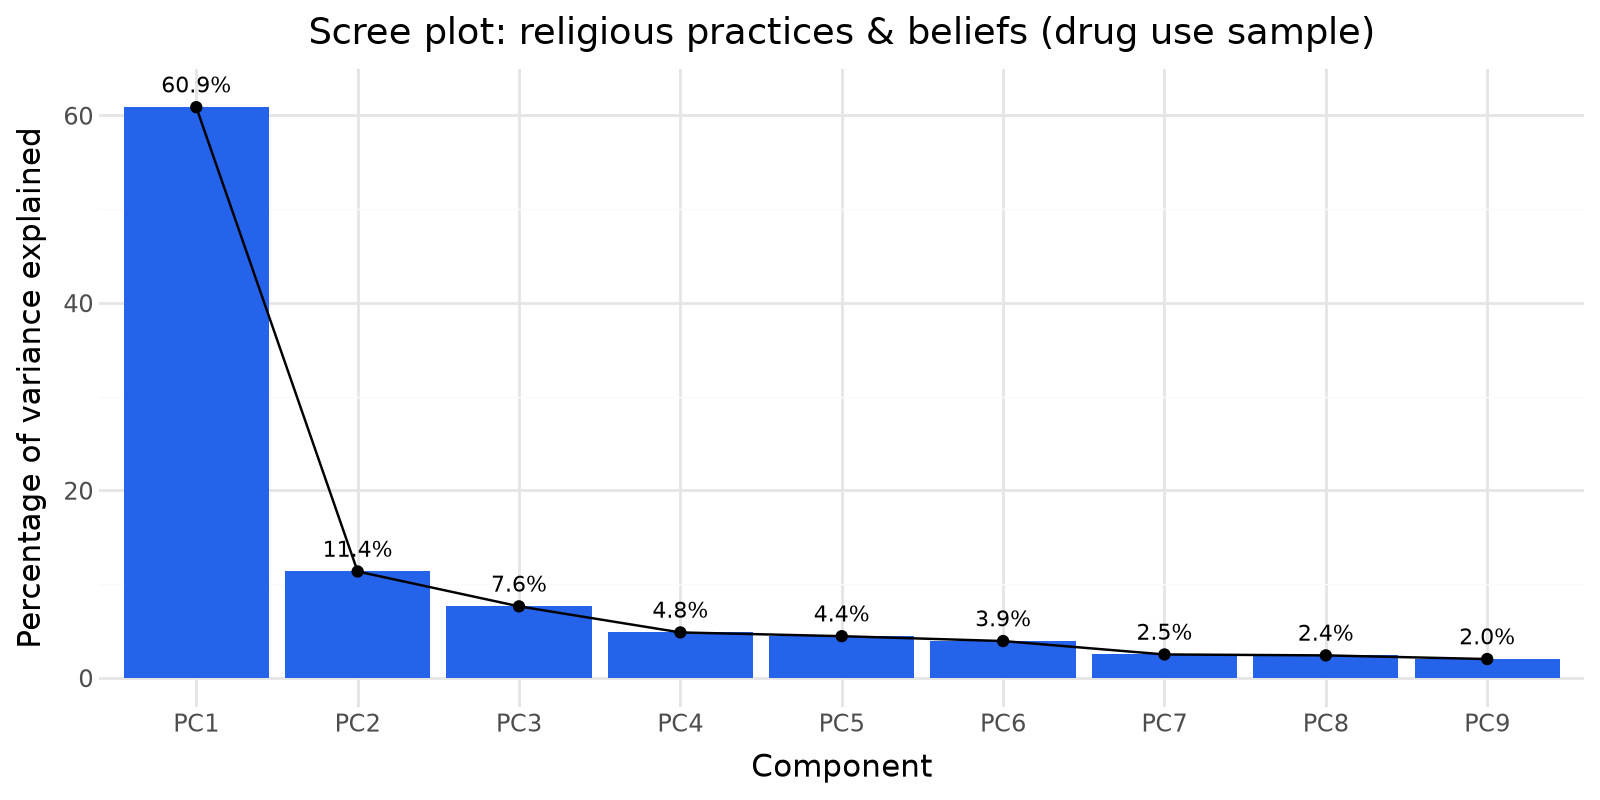


Loadings (|value| > 0.3 is meaningful)


,PC1,PC2
PRACTICES: Praying Frequency,0.88,0.10
PRACTICES: Saying Grace,0.69,-0.06
PRACTICES: Praying for Self,0.83,0.28
PRACTICES: Praying for Close People,0.83,0.37
PRACTICES: Praying for Others,0.75,0.40
PRACTICES: Attending Services,0.78,-0.11
BELIEFS: Closeness to God,0.80,-0.00
BELIEFS: Bible Inerrancy,0.73,-0.55
BELIEFS: Bible as Moral Guide,0.71,-0.57



Odds ratios and average marginal effects


,model,component,OR,OR low,OR high,p,AME (pp),AME low,AME high
0,PC1 only,PC1,0.600,0.514,0.700,0.000,-2.827,-3.732,-1.923
1,PC1 + PC2,PC1,0.598,0.512,0.698,0.000,-2.845,-3.750,-1.940
2,PC1 + PC2,PC2,1.171,0.999,1.372,0.051,0.872,-0.010,1.754


Pseudo R²: PC1 only = 0.032, PC1 + PC2 = 0.035


In [9]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import plotnine as p9
from stargazer.stargazer import Stargazer

BLUE, MUTED = "#2563EB", "#9CA3AF"

# 1. Load and rename
df = pd.read_stata("chrisu.DTA", convert_categoricals=False).copy()
df = df.rename(columns={
    "V25": "pray_freq", "V26": "table_grace", "V27": "pray_self",
    "V28": "pray_close", "V29": "pray_others", "V34": "attend_services",
    "V30": "god_close", "V39": "bible_inerrant", "V41": "bible_morality",
    "V79": "drug_freq",
})
df["god_close"] = 6 - df["god_close"]       # V30: 1 = Very close ... 5 = No closeness -> now 5 = Very close

# 2. Outcome: 1 = any illegal drug use, 0 = none
df["drug_use"] = np.where(df["drug_freq"].isna(), np.nan, (df["drug_freq"] > 0).astype(int))

practices = ["pray_freq", "table_grace", "pray_self", "pray_close", "pray_others", "attend_services"]
beliefs   = ["god_close", "bible_inerrant", "bible_morality"]
items     = practices + beliefs

item_labels = {
    "pray_freq": "PRACTICES: Praying Frequency", "table_grace": "PRACTICES: Saying Grace",
    "pray_self": "PRACTICES: Praying for Self", "pray_close": "PRACTICES: Praying for Close People",
    "pray_others": "PRACTICES: Praying for Others", "attend_services": "PRACTICES: Attending Services",
    "god_close": "BELIEFS: Closeness to God", "bible_inerrant": "BELIEFS: Bible Inerrancy",
    "bible_morality": "BELIEFS: Bible as Moral Guide",
}

# 3. One common sample
cd = df[["drug_use"] + items].dropna().copy()
print(f"N = {len(cd)} | drug users = {int(cd['drug_use'].sum())} | base rate = {cd['drug_use'].mean():.1%}")

# 4. Standardise items (mean 0, SD 1), then PCA on the correlation matrix
z = (cd[items] - cd[items].mean()) / cd[items].std()
eigval, eigvec = np.linalg.eigh(np.corrcoef(z.T))
order = eigval.argsort()[::-1]                     # largest component first
eigval, eigvec = eigval[order], eigvec[:, order]

# 5. Scree table
pcs = [f"PC{i+1}" for i in range(len(items))]
scree = pd.DataFrame({
    "eigenvalue": eigval,
    "% variance": eigval / eigval.sum() * 100,
    "cumulative %": (eigval / eigval.sum() * 100).cumsum(),
}, index=pcs).round(2)
print("\nScree table")
display(scree)
print(f"Kaiser rule (eigenvalue > 1): keep {int((eigval > 1).sum())} component(s)")

# 6. Scree plot
scree_df = scree.reset_index().rename(columns={"index": "PC"})
scree_df["PC"] = pd.Categorical(scree_df["PC"], categories=pcs)
scree_df["label"] = scree_df["% variance"].round(1).astype(str) + "%"
scree_plot = (p9.ggplot(scree_df, p9.aes("PC", "% variance"))
              + p9.geom_col(fill=BLUE)
              + p9.geom_line(p9.aes(group=1)) + p9.geom_point()
              + p9.geom_text(p9.aes(label="label"), va="bottom", nudge_y=1, size=8)
              + p9.labs(title="Scree plot: religious practices & beliefs (drug use sample)",
                        x="Component", y="Percentage of variance explained")
              + p9.theme_minimal() + p9.theme(figure_size=(8, 4)))
display(scree_plot)

# 7. Loadings for PC1 and PC2
loadings = pd.DataFrame(eigvec[:, :2] * np.sqrt(eigval[:2]), index=items, columns=["PC1", "PC2"])
# Signs in PCA are arbitrary: make PC1 high = more religious, PC2 high = more "pray for others"
sign = np.array([np.sign(loadings["PC1"].sum()), np.sign(loadings.loc["pray_others", "PC2"])])
loadings = loadings * sign
print("\nLoadings (|value| > 0.3 is meaningful)")
display(loadings.rename(index=item_labels).round(2))

# 8. Component scores for each student (standardised: 1 unit = 1 SD)
scores = (z.values @ eigvec[:, :2]) * sign
cd["PC1"] = scores[:, 0] / scores[:, 0].std(ddof=1)
cd["PC2"] = scores[:, 1] / scores[:, 1].std(ddof=1)

# 9. Logit: drug use on the components
m_pc1 = smf.logit("drug_use ~ PC1", data=cd).fit(disp=0)          # main component only
m_pc2 = smf.logit("drug_use ~ PC1 + PC2", data=cd).fit(disp=0)    # adds the secondary component

sg_pca = Stargazer([m_pc1, m_pc2])
sg_pca.dependent_variable_name("Illegal Drug Use")
sg_pca.custom_columns(["PC1 only", "PC1 + PC2"], [1, 1])
sg_pca.covariate_order(["PC1", "PC2", "Intercept"])
sg_pca.rename_covariates({"PC1": "PC1: General religiosity",
                          "PC2": "PC2: Devotional vs doctrinal"})
sg_pca.add_custom_notes(["Components standardised (per 1 SD). Standard errors in parentheses."])
display(sg_pca)

# 10. Odds ratios and average marginal effects (percentage points)
rows = []
for name, m in [("PC1 only", m_pc1), ("PC1 + PC2", m_pc2)]:
    ci = np.exp(m.conf_int())
    me = m.get_margeff(at="overall").summary_frame()
    for v in [x for x in ["PC1", "PC2"] if x in m.params]:
        rows.append({"model": name, "component": v,
                     "OR": np.exp(m.params[v]), "OR low": ci.loc[v, 0], "OR high": ci.loc[v, 1],
                     "p": m.pvalues[v],
                     "AME (pp)": me.loc[v, "dy/dx"] * 100,
                     "AME low": me.loc[v, "Conf. Int. Low"] * 100,
                     "AME high": me.loc[v, "Cont. Int. Hi."] * 100})   # statsmodels' own spelling
print("\nOdds ratios and average marginal effects")
display(pd.DataFrame(rows).round(3))
print(f"Pseudo R²: PC1 only = {m_pc1.prsquared:.3f}, PC1 + PC2 = {m_pc2.prsquared:.3f}")